In [20]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, peak_widths

ROOT = Path.cwd()
if not (ROOT / 'asd_finite_temperature').exists():
    ROOT = Path('/home/senji77/akhyar/research/notebooks/ANSW')

OUTPUT = ROOT / 'asd_mode_tracking'
OUTPUT.mkdir(parents=True, exist_ok=True)
REPLICA_DIR = ROOT / 'asd_replica_profiles'

FILES = {
    0.1: ROOT / 'asd_2d_results' / 'asd_dynamical_structure_factor_T0p1.npz',
    0.3: ROOT / 'asd_finite_temperature' / 'asd_dynamical_structure_factor_T0p3.npz',
    0.5: ROOT / 'asd_finite_temperature' / 'asd_dynamical_structure_factor_T0p5.npz',
    1.0: ROOT / 'asd_finite_temperature' / 'asd_dynamical_structure_factor_T1p0.npz'
}

MODELS = [('dmi', 'DMI-x', '#C00032'), ('frustration', 'Frustration', '#0055CC')]
Q_TARGETS = [(np.pi / 2, 0.0), (np.pi / 2, np.pi / 4)]
DATA = {}
REPLICA = {}

for t, file in FILES.items():
    if not file.exists():
        print('Not found:', file)
        continue
    with np.load(file) as z:
        DATA[t] = {k: z[k].copy() for k in z.files}
    rp = REPLICA_DIR / ('asd_replica_profiles_T' + f'{t:.1f}'.replace('.', 'p') + '.npz')
    if rp.exists():
        with np.load(rp) as z:
            REPLICA[t] = {k: z[k].copy() for k in z.files}
    d = DATA[t]
    for model, _, _ in MODELS:
        assert d['S_'+model].shape == (len(d['omega']), len(d['qx']), len(d['qy']))
    print(f'T={t:.1f} frequency_resolution={d["omega"][1]-d["omega"][0]:.6f} ASD_replicas={int(d["n_replicas"])}',
          'replica_profiles=' + str(t in REPLICA))

TEMPERATURES = sorted(DATA)
assert TEMPERATURES, 'No ASD spectra found'
print('Output:', OUTPUT)

T=0.1 frequency_resolution=0.098175 ASD_replicas=4 replica_profiles=True
T=0.3 frequency_resolution=0.098175 ASD_replicas=4 replica_profiles=True
T=0.5 frequency_resolution=0.098175 ASD_replicas=4 replica_profiles=True
T=1.0 frequency_resolution=0.098175 ASD_replicas=4 replica_profiles=True
Output: /home/senji77/akhyar/research/notebooks/ANSW/asd_mode_tracking


In [21]:
q0 = np.pi / 4
J = float(DATA[TEMPERATURES[0]]['J'])
D = float(DATA[TEMPERATURES[0]]['D'])
J2 = float(DATA[TEMPERATURES[0]]['J2'])
OMEGA_MIN = 0.20
OMEGA_MAX = 8.0
MAX_ANCHOR_DISTANCE = 0.55
MAX_TRACK_STEP = 0.65
SMOOTH_BINS = 0.6
BOOTSTRAP_SAMPLES = 400

for t in TEMPERATURES:
    d = DATA[t]
    assert np.isclose(float(d['J']), J)
    assert np.isclose(float(d['D']), D)
    assert np.isclose(float(d['J2']), J2)
    assert np.allclose(d['qx'], DATA[TEMPERATURES[0]]['qx'])
    assert np.allclose(d['qy'], DATA[TEMPERATURES[0]]['qy'])


def lswt_2d(kx, ky, model):
    cq = np.cos(q0)
    cx = np.cos(kx)
    cy = np.cos(ky)
    if model == 'dmi':
        lam = 2 * J * (1 + cq) + 2 * D * np.sin(q0)
        A = lam - 2 * J * (cx + cy)
        B = lam - 2 * ((J * cq + D * np.sin(q0)) * cx + J * cy)
    else:
        lam = 2 * J * (1 + cq) - 2 * J2 * np.cos(2 * q0)
        A = lam - 2 * J * (cx + cy) + 2 * J2 * np.cos(2 * kx)
        B = lam - 2 * J * (cq * cx + cy) + 2 * J2 * np.cos(2 * q0) * np.cos(2 * kx)
    return float(np.sqrt(max(A * B, 0.0)))


def theory_candidates(kx, ky, model):
    return {
        'unshifted': lswt_2d(kx, ky, model),
        'minus_q0': lswt_2d(kx - q0, ky, model),
        'plus_q0': lswt_2d(kx + q0, ky, model)
    }


def get_replica_spectra(t, model, target):
    if t not in REPLICA:
        return None
    d = REPLICA[t]
    key = 'S_'+model+'_replica'
    if key not in d:
        return None
    stored_q = np.asarray(d['q_targets'])
    iq = np.argmin(np.sum((stored_q-np.asarray(target))**2, axis=1))
    if np.linalg.norm(stored_q[iq] - target) > 1e-5:
        return None
    assert np.allclose(d['omega'], DATA[t]['omega'])
    assert d[key].ndim == 3
    return np.asarray(d[key][:, :, iq], dtype=np.float64)


def get_profile(t, model, target):
    rep = get_replica_spectra(t, model, target)
    if rep is not None:
        return rep.mean(axis=0)
    d = DATA[t]
    ix = np.argmin(np.abs(d['qx']-target[0]))
    iy = np.argmin(np.abs(d['qy']-target[1]))
    return np.asarray(d['S_'+model][:, ix, iy], dtype=np.float64)

In [22]:
def spectral_peaks(omega, spectrum):
    selection = (omega >= OMEGA_MIN) & (omega <= OMEGA_MAX)
    w = np.asarray(omega[selection], dtype=float)
    s = np.maximum(np.asarray(spectrum[selection], dtype=float), 0)
    smooth = gaussian_filter1d(s, sigma=SMOOTH_BINS)
    reference = float(np.max(smooth))
    if reference <= 0:
        return []
    smooth = smooth / reference
    spacing = float(np.median(np.diff(w)))
    peaks, props = find_peaks(smooth, prominence=0.05, height=0.06, distance=2)
    widths = peak_widths(smooth, peaks, rel_height=0.5)[0] * spacing if len(peaks) else np.empty(0)
    return [
        {'omega':float(w[p]), 'width':float(widths[i]),
         'height':float(smooth[p]), 'prominence':float(props['prominences'][i])}
        for i, p in enumerate(peaks)
    ]


def match_unique(predictions, peaks, tolerance):
    pairs = []
    for branch, reference in predictions.items():
        for i, peak in enumerate(peaks):
            separation = abs(peak['omega'] - reference)
            if separation <= tolerance:
                pairs.append((separation, -peak['prominence'], branch, i))
    assignment = {}
    assigned_peaks = set()
    for _, _, branch, i in sorted(pairs):
        if branch not in assignment and i not in assigned_peaks:
            assignment[branch] = peaks[i]
            assigned_peaks.add(i)
    return assignment


TRACKED = []
for model, name, color in MODELS:
    for target in Q_TARGETS:
        d_first = DATA[TEMPERATURES[0]]
        kx = float(d_first['qx'][np.argmin(np.abs(d_first['qx']-target[0]))])
        ky = float(d_first['qy'][np.argmin(np.abs(d_first['qy']-target[1]))])
        target_grid = (kx, ky)
        theories = theory_candidates(kx, ky, model)
        history = {}
        for t in TEMPERATURES:
            peaks = spectral_peaks(DATA[t]['omega'], get_profile(t, model, target_grid))
            if t == TEMPERATURES[0]:
                assign = match_unique(theories, peaks, MAX_ANCHOR_DISTANCE)
                for branch in assign:
                    history[branch] = assign[branch]['omega']
                active_branches = list(assign)
            else:
                assign = match_unique(history, peaks, MAX_TRACK_STEP)
                for branch in assign:
                    history[branch] = assign[branch]['omega']
            for branch in active_branches:
                p = assign.get(branch)
                TRACKED.append({
                    'T':float(t), 'model':name, 'model_key':model,
                    'qx_pi':kx/np.pi, 'qy_pi':ky/np.pi,
                    'branch_candidate':branch, 'omega_LSWT_reference':float(theories[branch]),
                    'omega_tracked':float(p['omega']) if p is not None else np.nan,
                    'apparent_width':float(p['width']) if p is not None else np.nan,
                    'relative_peak_height':float(p['height']) if p is not None else np.nan,
                    'prominence':float(p['prominence']) if p is not None else np.nan,
                    'status':'candidate_matched' if p is not None else 'not_resolved',
                    'qx':kx, 'qy':ky
                })
        print(f'{name} q/pi=({kx/np.pi:.2f},{ky/np.pi:.2f}) anchored candidates:', active_branches)

assert TRACKED, 'No candidate branches resolved at initial temperature'

DMI-x q/pi=(0.50,0.00) anchored candidates: ['minus_q0', 'unshifted', 'plus_q0']
DMI-x q/pi=(0.50,0.25) anchored candidates: ['minus_q0', 'unshifted', 'plus_q0']
Frustration q/pi=(0.50,0.00) anchored candidates: ['unshifted']
Frustration q/pi=(0.50,0.25) anchored candidates: ['minus_q0', 'unshifted', 'plus_q0']


In [23]:
RNG = np.random.default_rng(20261115)
for row in TRACKED:
    row.update(omega_ci_low=np.nan, omega_ci_high=np.nan,
               width_ci_low=np.nan, width_ci_high=np.nan,
               bootstrap_valid_fraction=np.nan, independent_replicas=0)
    if not np.isfinite(row['omega_tracked']):
        continue
    t = row['T']
    model = row['model_key']
    target = (row['qx'], row['qy'])
    spectra = get_replica_spectra(t, model, target)
    if spectra is None or len(spectra) < 4:
        continue
    row['independent_replicas'] = len(spectra)
    omega = DATA[t]['omega']
    dw = float(np.median(np.diff(omega)))
    center = row['omega_tracked']
    near = max(3*dw, 0.35)
    estimates = []
    widths = []
    for _ in range(BOOTSTRAP_SAMPLES):
        draw = RNG.integers(0, len(spectra), size=len(spectra))
        mean_profile = spectra[draw].mean(axis=0)
        candidates = spectral_peaks(omega, mean_profile)
        nearby = [p for p in candidates if abs(p['omega']-center) < near]
        if not nearby:
            continue
        p = min(nearby, key=lambda item: abs(item['omega']-center))
        estimates.append(p['omega'])
        widths.append(p['width'])
    valid_fraction = len(estimates) / BOOTSTRAP_SAMPLES
    row['bootstrap_valid_fraction'] = valid_fraction
    if valid_fraction >= 0.8:
        row['omega_ci_low'], row['omega_ci_high'] = np.quantile(estimates, [0.025,0.975])
        row['width_ci_low'], row['width_ci_high'] = np.quantile(widths, [0.025,0.975])

fieldnames = [
    'T','model','qx_pi','qy_pi','branch_candidate','omega_LSWT_reference',
    'omega_tracked','omega_ci_low','omega_ci_high',
    'apparent_width','width_ci_low','width_ci_high',
    'relative_peak_height','prominence','status',
    'bootstrap_valid_fraction','independent_replicas'
]

with open(OUTPUT / 'candidate_mode_tracking.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    for row in TRACKED:
        writer.writerow({key:row.get(key) for key in fieldnames})

print('Candidate modes:', len(TRACKED))
print('Rows with replica-bootstrap confidence intervals:', sum(np.isfinite(r['omega_ci_low']) for r in TRACKED))
if not REPLICA:
    print('No per-replica ASD spectra. Confidence intervals intentionally omitted.')

Candidate modes: 40
Rows with replica-bootstrap confidence intervals: 24


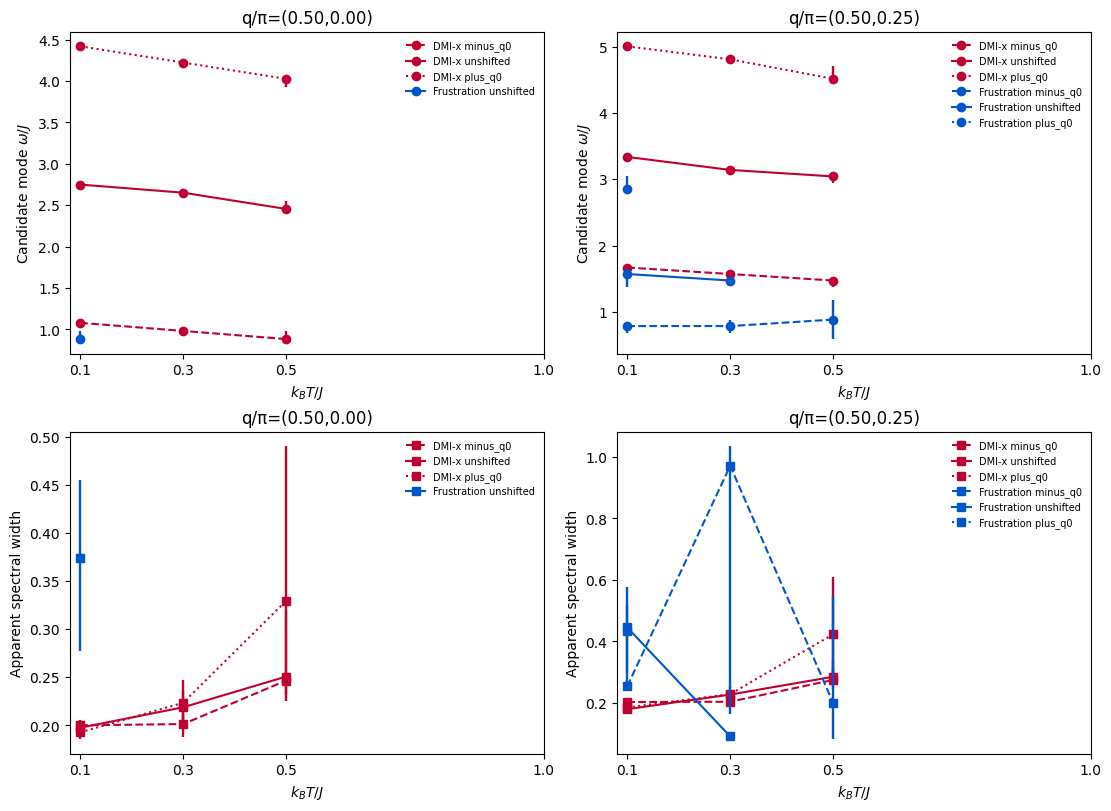

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
styles = {'unshifted':'-', 'minus_q0':'--', 'plus_q0':':'}

for col, target in enumerate(Q_TARGETS):
    for model, name, color in MODELS:
        selected = [r for r in TRACKED if r['model_key']==model
                    and np.isclose(r['qx_pi'],target[0]/np.pi)
                    and np.isclose(r['qy_pi'],target[1]/np.pi)]
        for branch in dict.fromkeys(r['branch_candidate'] for r in selected):
            subset = sorted((r for r in selected if r['branch_candidate']==branch), key=lambda r:r['T'])
            tt = np.array([r['T'] for r in subset])
            yy = np.array([r['omega_tracked'] for r in subset])
            axes[0,col].plot(tt, yy, marker='o', color=color, ls=styles[branch],
                             label=name+' '+branch)
            for row in subset:
                if np.isfinite(row['omega_ci_low']):
                    axes[0,col].vlines(row['T'],row['omega_ci_low'],row['omega_ci_high'],color=color,linewidth=1.7)
            ww = np.array([r['apparent_width'] for r in subset])
            axes[1,col].plot(tt, ww, marker='s', color=color, ls=styles[branch],
                             label=name+' '+branch)
            for row in subset:
                if np.isfinite(row['width_ci_low']):
                    axes[1,col].vlines(row['T'],row['width_ci_low'],row['width_ci_high'],color=color,linewidth=1.7)
    for ax in axes[:,col]:
        ax.set_title(f'q/π=({target[0]/np.pi:.2f},{target[1]/np.pi:.2f})')
        ax.set_xlabel(r'$k_B T/J$')
        ax.set_xticks(TEMPERATURES)
    axes[0,col].set_ylabel(r'Candidate mode $\omega/J$')
    axes[1,col].set_ylabel('Apparent spectral width')
    axes[0,col].legend(fontsize=7,frameon=False)
    axes[1,col].legend(fontsize=7,frameon=False)

fig.savefig(OUTPUT/'candidate_mode_vs_temperature.pdf',bbox_inches='tight')
fig.savefig(OUTPUT/'candidate_mode_vs_temperature.png',dpi=300,bbox_inches='tight')
plt.show()

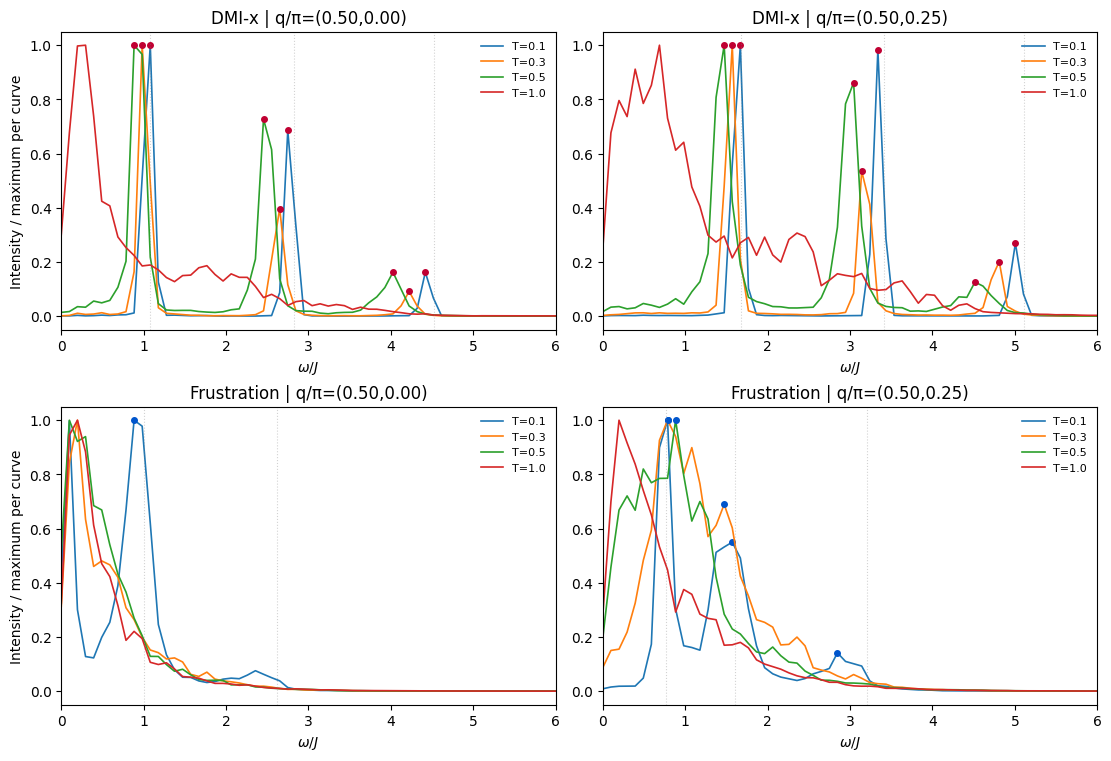

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5),constrained_layout=True)
for row,(model,name,color) in enumerate(MODELS):
    for col,target in enumerate(Q_TARGETS):
        ax = axes[row,col]
        d = DATA[TEMPERATURES[0]]
        kx = float(d['qx'][np.argmin(abs(d['qx']-target[0]))])
        ky = float(d['qy'][np.argmin(abs(d['qy']-target[1]))])
        for t in TEMPERATURES:
            omega = DATA[t]['omega']
            spec = get_profile(t,model,(kx,ky))
            ax.plot(omega,spec / max(float(spec.max()),1e-20),lw=1.2,label=f'T={t:.1f}')
            points = [r for r in TRACKED if r['model_key']==model and np.isclose(r['T'],t)
                      and np.isclose(r['qx'],kx) and np.isclose(r['qy'],ky)]
            for p in points:
                if np.isfinite(p['omega_tracked']):
                    i = np.argmin(abs(omega-p['omega_tracked']))
                    ax.plot([omega[i]],[spec[i]/max(float(spec.max()),1e-20)],marker='o',ms=4,color=color)
        for v in theory_candidates(kx,ky,model).values():
            if OMEGA_MIN <= v <= OMEGA_MAX:
                ax.axvline(v,color='gray',ls=':',alpha=.35,lw=.8)
        ax.set_xlim(0,6)
        ax.set_title(f'{name} | q/π=({kx/np.pi:.2f},{ky/np.pi:.2f})')
        ax.set_xlabel(r'$\omega/J$')
        if col == 0:
            ax.set_ylabel('Intensity / maximum per curve')
        ax.legend(frameon=False,fontsize=8)

fig.savefig(OUTPUT/'candidate_mode_peak_profiles.pdf',bbox_inches='tight')
fig.savefig(OUTPUT/'candidate_mode_peak_profiles.png',dpi=300,bbox_inches='tight')
plt.show()

In [26]:
summary = []
for t in TEMPERATURES:
    for model,name,color in MODELS:
        d = DATA[t]
        energies = np.asarray(d['energy_'+model],dtype=float)
        drift = float(np.max(np.abs(energies-energies[0]) / np.maximum(abs(energies[0]),1e-10)))
        summary.append(dict(T=t,model=name,n_replicas_old=int(d['n_replicas']),
                            max_relative_energy_drift=drift,
                            has_replica_profiles=t in REPLICA,
                            n_replicas_new=int(REPLICA[t]['S_'+model+'_replica'].shape[0]) if t in REPLICA else 0))

with open(OUTPUT/'analysis_quality_checks.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

for row in summary:
    print(f"T={row['T']:.1f} {row['model']:12s} energy_drift={row['max_relative_energy_drift']:.4e} n_replicas_new={row['n_replicas_new']}")
print('Results saved to:',OUTPUT.resolve())
print('Branch matching is a provisional LSWT-guided identification, not proof of mode identity.')
print('Widths are resolution-limited apparent widths, not intrinsic damping rates.')

T=0.1 DMI-x        energy_drift=2.2687e-05 n_replicas_new=16
T=0.1 Frustration  energy_drift=6.6763e-06 n_replicas_new=16
T=0.3 DMI-x        energy_drift=4.9984e-05 n_replicas_new=16
T=0.3 Frustration  energy_drift=1.3927e-05 n_replicas_new=16
T=0.5 DMI-x        energy_drift=6.1285e-05 n_replicas_new=16
T=0.5 Frustration  energy_drift=1.5554e-05 n_replicas_new=16
T=1.0 DMI-x        energy_drift=4.5612e-05 n_replicas_new=16
T=1.0 Frustration  energy_drift=1.4232e-05 n_replicas_new=16
Results saved to: /home/senji77/akhyar/research/notebooks/ANSW/asd_mode_tracking
Branch matching is a provisional LSWT-guided identification, not proof of mode identity.
Widths are resolution-limited apparent widths, not intrinsic damping rates.


In [27]:

from pathlib import Path
import pandas as pd

folder = Path("asd_mode_tracking")

if not folder.exists():
    folder = Path(
        "/home/senji77/akhyar/research/notebooks/ANSW/asd_mode_tracking"
    )

df = pd.read_csv(folder / "candidate_mode_tracking.csv")

print("Total candidate modes:", len(df))
print("Successfully tracked:", df["omega_tracked"].notna().sum())
print("Rows with 95% CI:", df["omega_ci_low"].notna().sum())

print("\nTracking summary:")
print(
    df.groupby(["T", "model"])["status"]
    .value_counts()
    .to_string()
)

print("\nModes with confidence intervals:")

columns = [
    "T",
    "model",
    "qx_pi",
    "qy_pi",
    "branch_candidate",
    "omega_tracked",
    "omega_ci_low",
    "omega_ci_high",
    "apparent_width",
    "bootstrap_valid_fraction",
    "independent_replicas"
]

print(
    df.loc[df["omega_ci_low"].notna(), columns]
    .round(4)
    .to_string(index=False)
)


Total candidate modes: 40
Successfully tracked: 25
Rows with 95% CI: 24

Tracking summary:
T    model        status           
0.1  DMI-x        candidate_matched    6
     Frustration  candidate_matched    4
0.3  DMI-x        candidate_matched    6
     Frustration  candidate_matched    2
                  not_resolved         2
0.5  DMI-x        candidate_matched    6
     Frustration  not_resolved         3
                  candidate_matched    1
1.0  DMI-x        not_resolved         6
     Frustration  not_resolved         4

Modes with confidence intervals:
  T       model  qx_pi  qy_pi branch_candidate  omega_tracked  omega_ci_low  omega_ci_high  apparent_width  bootstrap_valid_fraction  independent_replicas
0.1       DMI-x    0.5   0.00         minus_q0         1.0799        1.0799         1.0799          0.2001                    1.0000                    16
0.1       DMI-x    0.5   0.00        unshifted         2.7489        2.7489         2.7489          0.1975             

In [28]:

from pathlib import Path
import numpy as np

folder = Path("mc_temperature_snapshots")

for file in sorted(folder.glob("*.npy")):
    spins = np.load(file, mmap_mode="r")
    print(file.name, spins.shape)


spins_dmi_T0p3.npy (4, 32, 64, 64, 3)
spins_dmi_T0p5.npy (4, 32, 64, 64, 3)
spins_dmi_T1p0.npy (4, 32, 64, 64, 3)
spins_frustration_T0p3.npy (4, 32, 64, 64, 3)
spins_frustration_T0p5.npy (4, 32, 64, 64, 3)
spins_frustration_T1p0.npy (4, 32, 64, 64, 3)


In [29]:

from pathlib import Path
import numpy as np
import pandas as pd

folder = Path("mc_temperature_snapshots")

temperatures = [0.1, 0.3, 0.5, 1.0]
models = ["dmi", "frustration"]

q0 = np.pi / 4
results = []

for model in models:
    for t in temperatures:
        if t == 0.1:
            if model == "dmi":
                file = Path("production_dmi_x/spins_dmi_latest.npy")
            else:
                file = Path("spins_frustration_latest.npy")
        else:
            tag = f"{t:.1f}".replace(".", "p")
            file = folder / f"spins_{model}_T{tag}.npy"

        spins = np.load(file)

        if spins.ndim == 4:
            spins = spins[None, ...]

        n_snap, replicas, nx, ny, _ = spins.shape
        N = nx * ny

        qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
        qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

        iq = np.argmin(np.abs(qx - q0))
        iy = np.argmin(np.abs(qy))

        F = np.fft.fftshift(
            np.fft.fft2(spins, axes=(2, 3)),
            axes=(2, 3)
        )

        S_peak = np.sum(
            np.abs(F[:, :, iq, iy, :]) ** 2,
            axis=-1
        ) / (N ** 2)

        chi_x = np.mean(
            np.cross(spins, np.roll(spins, -1, axis=2)),
            axis=(2, 3)
        )

        order_replica = np.mean(S_peak, axis=0)
        chirality_replica = np.mean(chi_x[:, :, 0], axis=0)
        chirality_norm_replica = np.mean(
            np.linalg.norm(chi_x, axis=-1),
            axis=0
        )

        results.append({
            "model": model,
            "T": t,
            "S_peak": np.mean(order_replica),
            "S_peak_sem": np.std(order_replica, ddof=1) / np.sqrt(replicas),
            "chirality_x": np.mean(chirality_replica),
            "chirality_x_sem": np.std(chirality_replica, ddof=1) / np.sqrt(replicas),
            "chirality_norm": np.mean(chirality_norm_replica),
            "chirality_norm_sem": np.std(chirality_norm_replica, ddof=1) / np.sqrt(replicas)
        })

df_order = pd.DataFrame(results)
df_order.to_csv("magnetic_ordering_vs_temperature.csv", index=False)

print(df_order.round(5).to_string(index=False))


      model   T  S_peak  S_peak_sem  chirality_x  chirality_x_sem  chirality_norm  chirality_norm_sem
        dmi 0.1 0.45606     0.00075      0.67373          0.00011         0.67375             0.00011
        dmi 0.3 0.36997     0.00111      0.60470          0.00016         0.60477             0.00016
        dmi 0.5 0.28233     0.00129      0.53092          0.00031         0.53105             0.00031
        dmi 1.0 0.00387     0.00029      0.27982          0.00063         0.28008             0.00062
frustration 0.1 0.18899     0.01330     -0.00133          0.02884         0.26985             0.02220
frustration 0.3 0.03320     0.00269      0.00706          0.01295         0.22888             0.00461
frustration 0.5 0.00477     0.00024     -0.00273          0.00137         0.02877             0.00110
frustration 1.0 0.00097     0.00004      0.00052          0.00078         0.01503             0.00056


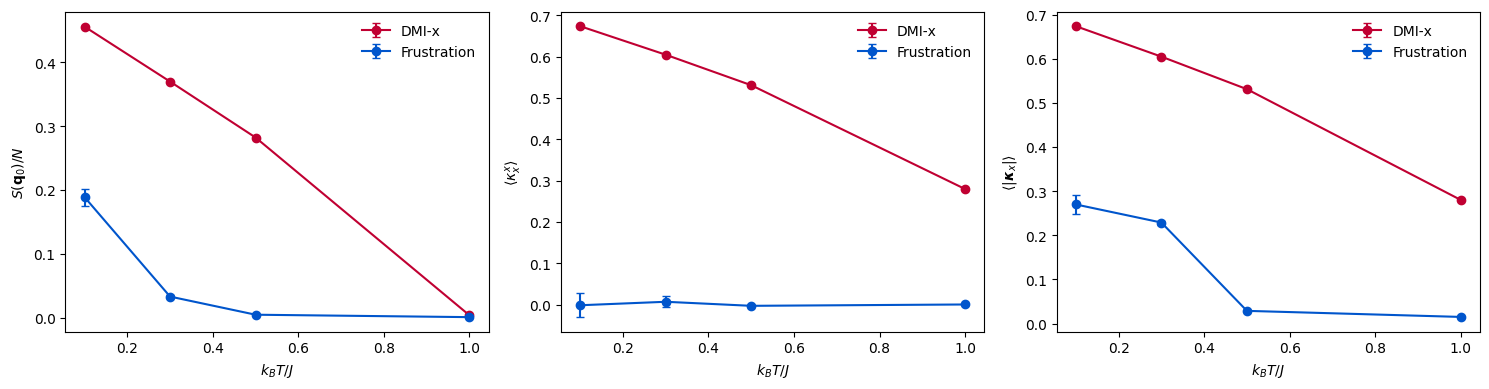

In [30]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for model, color, label in [
    ("dmi", "#C00032", "DMI-x"),
    ("frustration", "#0055CC", "Frustration")
]:
    data = df_order[df_order["model"] == model]

    axes[0].errorbar(
        data["T"], data["S_peak"],
        yerr=data["S_peak_sem"],
        marker="o", color=color, capsize=3, label=label
    )

    axes[1].errorbar(
        data["T"], data["chirality_x"],
        yerr=data["chirality_x_sem"],
        marker="o", color=color, capsize=3, label=label
    )

    axes[2].errorbar(
        data["T"], data["chirality_norm"],
        yerr=data["chirality_norm_sem"],
        marker="o", color=color, capsize=3, label=label
    )

axes[0].set_ylabel(r"$S(\mathbf{q}_0)/N$")
axes[1].set_ylabel(r"$\langle \kappa_x^x \rangle$")
axes[2].set_ylabel(r"$\langle |\boldsymbol{\kappa}_x| \rangle$")

for ax in axes:
    ax.set_xlabel(r"$k_BT/J$")
    ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("magnetic_ordering_vs_temperature.png", dpi=400, bbox_inches="tight")
plt.savefig("magnetic_ordering_vs_temperature.pdf", bbox_inches="tight")
plt.show()


In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

folder = Path("mc_temperature_snapshots")

temperatures = [0.1, 0.3, 0.5, 1.0]
models = ["dmi", "frustration"]

structure_factors = {}
results_q = []

for model in models:
    for t in temperatures:
        if t == 0.1:
            file = (
                Path("production_dmi_x/spins_dmi_latest.npy")
                if model == "dmi"
                else Path("spins_frustration_latest.npy")
            )
        else:
            tag = f"{t:.1f}".replace(".", "p")
            file = folder / f"spins_{model}_T{tag}.npy"

        spins = np.load(file)

        if spins.ndim == 4:
            spins = spins[None, ...]

        n_snap, replicas, nx, ny, _ = spins.shape
        N = nx * ny

        F = np.fft.fftshift(
            np.fft.fft2(spins, axes=(2, 3)),
            axes=(2, 3)
        )

        Sq = np.mean(
            np.sum(np.abs(F) ** 2, axis=-1),
            axis=(0, 1)
        ) / N**2

        qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
        qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

        iq = np.argmin(np.abs(qx - np.pi / 4))
        iy = np.argmin(np.abs(qy))

        Sq_test = Sq.copy()
        Sq_test[nx // 2, ny // 2] = 0

        i, j = np.unravel_index(np.argmax(Sq_test), Sq_test.shape)

        S_q0 = Sq[iq, iy]
        S_max = Sq_test[i, j]

        structure_factors[(model, t)] = (qx, qy, Sq)

        results_q.append({
            "model": model,
            "T": t,
            "qx_peak": qx[i],
            "qy_peak": qy[j],
            "S_max": S_max,
            "S_q0": S_q0,
            "S_q0_over_Smax": S_q0 / S_max,
            "peak_to_background": S_max / np.median(Sq)
        })

df_q = pd.DataFrame(results_q)

print(df_q.round(5).to_string(index=False))

df_q.to_csv("wavevector_stability.csv", index=False)


      model   T  qx_peak  qy_peak   S_max    S_q0  S_q0_over_Smax  peak_to_background
        dmi 0.1 -0.78540      0.0 0.45606 0.45606         1.00000        42039.171875
        dmi 0.3 -0.78540      0.0 0.36997 0.36997         1.00000        11306.468750
        dmi 0.5 -0.78540      0.0 0.28233 0.28233         1.00000         4988.257324
        dmi 1.0 -0.78540      0.0 0.00387 0.00387         1.00000           27.245449
frustration 0.1 -0.78540      0.0 0.18899 0.18899         1.00000        12676.149414
frustration 0.3 -0.68722      0.0 0.12265 0.03320         0.27065         2594.011963
frustration 0.5 -0.78540      0.0 0.00477 0.00477         1.00000           55.176048
frustration 1.0 -0.49087      0.0 0.00099 0.00097         0.97984            6.004200


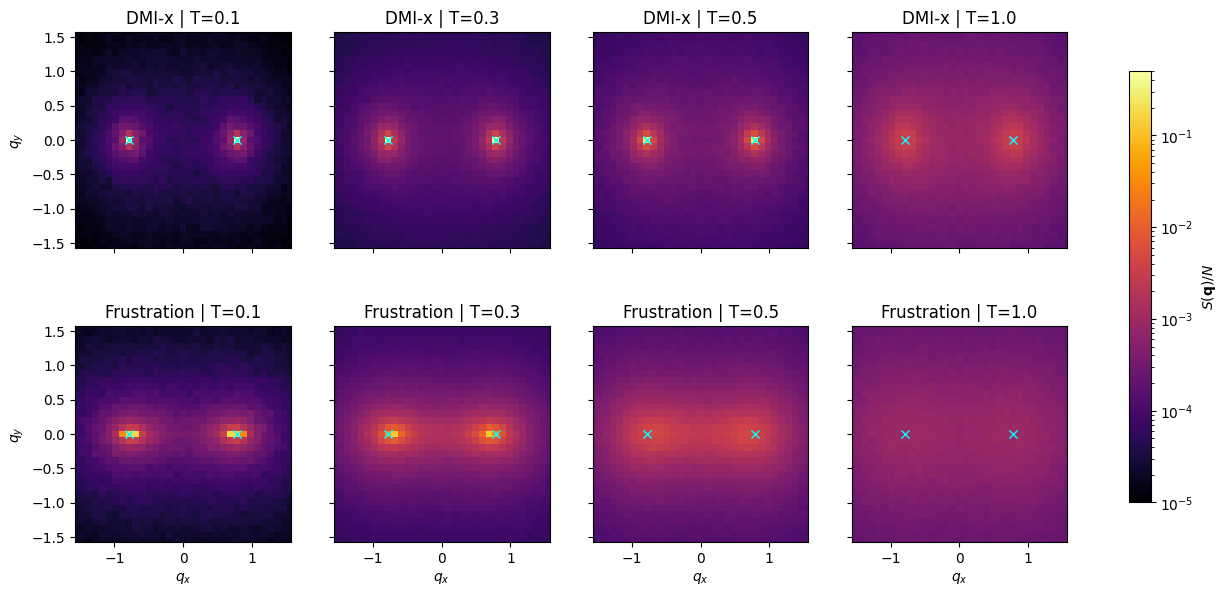

In [32]:

from matplotlib.colors import LogNorm

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)

for row, model in enumerate(models):
    for col, t in enumerate(temperatures):

        qx, qy, Sq = structure_factors[(model, t)]
        ax = axes[row, col]

        im = ax.pcolormesh(
            qx, qy, Sq.T,
            shading="nearest",
            cmap="inferno",
            norm=LogNorm(vmin=1e-5, vmax=0.5)
        )

        ax.scatter(
            [-np.pi/4, np.pi/4],
            [0, 0],
            marker="x",
            color="cyan",
            s=35,
            linewidths=1
        )

        ax.set_title(
            f"{'DMI-x' if model == 'dmi' else 'Frustration'} | T={t}"
        )

        ax.set_xlim(-np.pi/2, np.pi/2)
        ax.set_ylim(-np.pi/2, np.pi/2)
        ax.set_aspect("equal")

        if row == 1:
            ax.set_xlabel(r"$q_x$")

        if col == 0:
            ax.set_ylabel(r"$q_y$")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label=r"$S(\mathbf{q})/N$"
)

fig.savefig(
    "wavevector_stability.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    "wavevector_stability.pdf",
    bbox_inches="tight"
)

plt.show()


In [33]:

from collections import Counter

for model in ["dmi", "frustration"]:
    print(f"\n{model.upper()}")

    for t in [0.1, 0.3, 0.5, 1.0]:
        if t == 0.1:
            file = (
                Path("production_dmi_x/spins_dmi_latest.npy")
                if model == "dmi"
                else Path("spins_frustration_latest.npy")
            )
        else:
            tag = f"{t:.1f}".replace(".", "p")
            file = folder / f"spins_{model}_T{tag}.npy"

        spins = np.load(file)

        if spins.ndim == 4:
            spins = spins[None, ...]

        nx, ny = spins.shape[2:4]
        N = nx * ny

        F = np.fft.fftshift(
            np.fft.fft2(spins, axes=(2, 3)),
            axes=(2, 3)
        )

        Sq_replica = np.mean(
            np.sum(np.abs(F) ** 2, axis=-1) / N**2,
            axis=0
        )

        qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
        qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

        iq0 = np.argmin(np.abs(qx - np.pi / 4))
        iy0 = np.argmin(np.abs(qy))

        indices = np.where(
            (qx >= np.pi / 8) & (qx <= 3 * np.pi / 8)
        )[0]

        local_peaks = indices[
            np.argmax(Sq_replica[:, indices, iy0], axis=1)
        ]

        q_replica = qx[local_peaks]

        intensity_peak = Sq_replica[
            np.arange(len(q_replica)), local_peaks, iy0
        ]

        intensity_q0 = Sq_replica[:, iq0, iy0]

        counts = Counter(np.round(q_replica, 4))

        print(f"\nT = {t:.1f}")
        print("Wavevector counts:", dict(sorted(counts.items())))
        print("Mean peak intensity:", np.mean(intensity_peak))
        print("Mean intensity at q0:", np.mean(intensity_q0))
        print("Fraction at q0:", np.mean(local_peaks == iq0))



DMI

T = 0.1
Wavevector counts: {np.float64(0.7854): 32}
Mean peak intensity: 0.45605567
Mean intensity at q0: 0.45605567
Fraction at q0: 1.0

T = 0.3
Wavevector counts: {np.float64(0.7854): 32}
Mean peak intensity: 0.36997312
Mean intensity at q0: 0.36997312
Fraction at q0: 1.0

T = 0.5
Wavevector counts: {np.float64(0.7854): 32}
Mean peak intensity: 0.28232932
Mean intensity at q0: 0.28232932
Fraction at q0: 1.0

T = 1.0
Wavevector counts: {np.float64(0.4909): 1, np.float64(0.589): 2, np.float64(0.6872): 9, np.float64(0.7854): 13, np.float64(0.8836): 5, np.float64(0.9817): 2}
Mean peak intensity: 0.0046616048
Mean intensity at q0: 0.0038748123
Fraction at q0: 0.40625

FRUSTRATION

T = 0.1
Wavevector counts: {np.float64(0.6872): 20, np.float64(0.7854): 12}
Mean peak intensity: 0.22640502
Mean intensity at q0: 0.18899333
Fraction at q0: 0.375

T = 0.3
Wavevector counts: {np.float64(0.6872): 32}
Mean peak intensity: 0.12264964
Mean intensity at q0: 0.033195637
Fraction at q0: 0.0

T = 

In [34]:

from pathlib import Path
import numpy as np

J_check = 1.0
J2_check = J_check / (4 * np.cos(np.pi / 4))

for t in [0.1, 0.3]:

    if t == 0.1:
        file = Path("spins_frustration_latest.npy")
    else:
        file = Path("mc_temperature_snapshots/spins_frustration_T0p3.npy")

    spins = np.load(file)

    if spins.ndim == 4:
        spins = spins[None, ...]

    n_snap, replicas, nx, ny, _ = spins.shape
    N = nx * ny

    spin_x1 = np.roll(spins, -1, axis=2)
    spin_y1 = np.roll(spins, -1, axis=3)
    spin_x2 = np.roll(spins, -2, axis=2)

    energy = (
        -J_check * np.sum(spins * spin_x1, axis=-1)
        -J_check * np.sum(spins * spin_y1, axis=-1)
        +J2_check * np.sum(spins * spin_x2, axis=-1)
    )

    energy_replica = np.mean(
        np.sum(energy, axis=(2, 3)) / N,
        axis=0
    )

    F = np.fft.fftshift(
        np.fft.fft2(spins, axes=(2, 3)),
        axes=(2, 3)
    )

    Sq_replica = np.mean(
        np.sum(np.abs(F) ** 2, axis=-1),
        axis=0
    ) / N**2

    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

    iq7 = np.argmin(np.abs(qx - 7 * 2 * np.pi / nx))
    iq8 = np.argmin(np.abs(qx - 8 * 2 * np.pi / nx))
    iy0 = np.argmin(np.abs(qy))

    I7 = Sq_replica[:, iq7, iy0]
    I8 = Sq_replica[:, iq8, iy0]

    dominant = np.where(I7 > I8, 7, 8)

    print(f"\nT = {t:.1f}")
    print("Mean energy per spin:", np.mean(energy_replica))
    print("Mean S(q7):", np.mean(I7))
    print("Mean S(q8):", np.mean(I8))

    for winding in [7, 8]:
        mask = dominant == winding

        if np.any(mask):
            print(
                f"q = {winding} * 2pi/L | "
                f"replicas = {np.sum(mask)} | "
                f"mean E/N = {np.mean(energy_replica[mask]):.6f} | "
                f"std E/N = {np.std(energy_replica[mask]):.6f}"
            )



T = 0.1
Mean energy per spin: -1.6029129103351814
Mean S(q7): 0.17698216
Mean S(q8): 0.18899333
q = 7 * 2pi/L | replicas = 20 | mean E/N = -1.602515 | std E/N = 0.001580
q = 8 * 2pi/L | replicas = 12 | mean E/N = -1.603577 | std E/N = 0.001180

T = 0.3
Mean energy per spin: -1.3782335241071213
Mean S(q7): 0.12264964
Mean S(q8): 0.033195637
q = 7 * 2pi/L | replicas = 32 | mean E/N = -1.378234 | std E/N = 0.003015


In [35]:
L = 64
N = L * L

REPLICAS = 32
N_PER_COLOR = (L // 4) * (L // 2)
ADAPT_EVERY = 500

print("REPLICAS =", REPLICAS)
print("N_PER_COLOR =", N_PER_COLOR)
print("ADAPT_EVERY =", ADAPT_EVERY)

REPLICAS = 32
N_PER_COLOR = 512
ADAPT_EVERY = 500


In [37]:
import numpy as np
from numba import cuda
from numba.cuda.random import create_xoroshiro128p_states